[ ] VERIFICAR: REMOÇÃO DE OUTLIERS POR IQR
    - está removendo filmes legítimos

## Importação e Início

In [166]:
# utilizar os Dataframes do Pandas para manipular as instâncias
import pandas as pd
import numpy as np
# matplotlib e seaborn para visualizar
import matplotlib.pyplot as plt
import seaborn as sns
# gdown para baixar os dados
import gdown
import os
from datetime import datetime
plt.style.use('ggplot') 

In [167]:
url = 'https://drive.google.com/file/d/10izoanxrZJnQzkV9UpPI-DX9bt2mYG62/view'
output = 'filmes.json'
if not os.path.exists("filmes.json"):
    gdown.download(url=url, output="filmes.json", quiet=False)

In [168]:
df = pd.read_json('filmes.json', orient='records')

### Registrar o tamanho inicial do DataFrame

In [169]:
tamanho_inicial = len(df)
print(f"Número inicial de registros: {tamanho_inicial}")

Número inicial de registros: 16541


### ***Análise de dados faltantes:***

### Converter dados faltantes "disfarçados" em NAN

In [171]:
movies = df.copy() # criar cópia mesmo?

movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["year"] = movies["release_date"].dt.year
movies["decade"] = (movies["year"] // 10 * 10)

zero_means_missing = ["budget", "revenue", "runtime"]
movies[zero_means_missing] = movies[zero_means_missing].replace(0, np.nan)

text_cols = ["overview", "tagline", "homepage", "imdb_id", "poster_path", "backdrop_path"]
movies[text_cols] = movies[text_cols].replace(r"^\s*$", np.nan, regex=True)

list_cols = ["genres", "production_companies", "production_countries",
             "spoken_languages", "origin_country"]

for col in list_cols:
    movies[col] = movies[col].apply(lambda x: np.nan if isinstance(x, list) and len(x) == 0 else x)


### Observar faltantes por coluna

In [172]:
missing = (movies.isna().sum().to_frame("n_faltantes")
          .assign(pct=lambda d: 100 * d["n_faltantes"] / len(movies))
          .sort_values("pct", ascending=False))
print(missing)

                       n_faltantes        pct
belongs_to_collection        13729  82.999819
homepage                     11154  67.432441
tagline                       4367  26.401064
imdb_id                       2499  15.107914
backdrop_path                 2066  12.490176
production_companies          1671  10.102170
production_countries          1492   9.020011
spoken_languages              1094   6.613869
runtime                       1066   6.444592
overview                       904   5.465208
genres                         372   2.248957
poster_path                    351   2.122000
origin_country                  67   0.405054
adult                            0   0.000000
budget                           0   0.000000
popularity                       0   0.000000
original_title                   0   0.000000
original_language                0   0.000000
id                               0   0.000000
revenue                          0   0.000000
release_date                     0

### Faltantes por época

In [173]:
cols = ["budget", "revenue", "runtime", "overview", "genres",
        "production_companies", "poster_path"]

by_decade = (movies.groupby("decade")[cols]
               .apply(lambda g: g.isna().mean() * 100)
               .round(1))

by_decade["n_filmes"] = movies.groupby("decade").size()

print(by_decade)

        budget  revenue  runtime  overview  genres  production_companies  \
decade                                                                     
1910       0.0      0.0      6.2       0.0     0.0                   0.0   
1920       0.0      0.0      0.0       0.0     0.0                   1.6   
1930       0.0      0.0      0.7       0.7     0.7                   1.3   
1940       0.0      0.0      0.5       0.5     0.0                   0.5   
1950       0.0      0.0      5.6       2.8     0.3                   3.5   
1960       0.0      0.0      9.1       2.0     0.0                   2.8   
1970       0.0      0.0      0.9       1.1     1.1                   3.7   
1980       0.0      0.0      4.2       4.2     0.3                   1.3   
1990       0.0      0.0      2.6       2.5     0.8                   3.2   
2000       0.0      0.0      1.4       1.1     0.8                   4.6   
2010       0.0      0.0      3.2       2.6     2.0                   8.3   
2020       0

### Heatmap

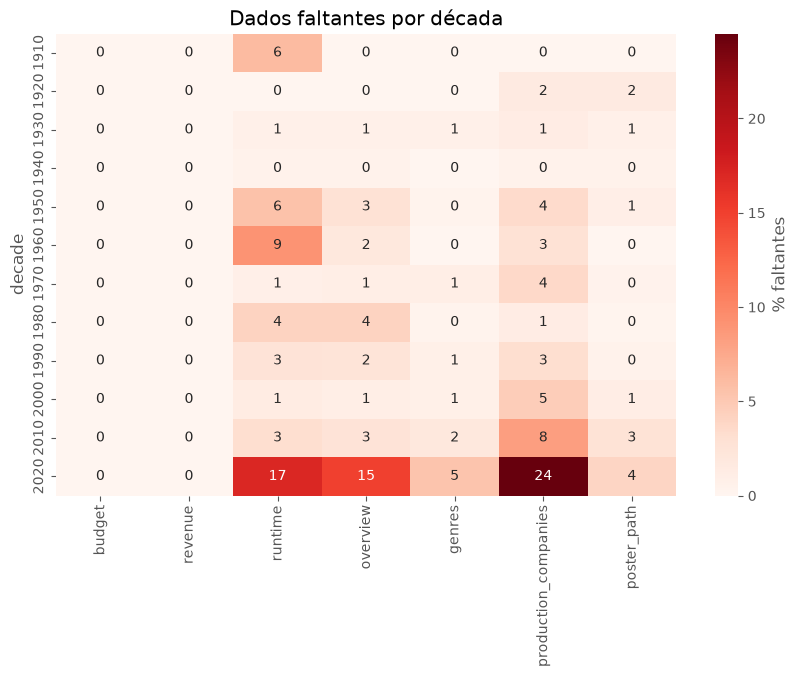

In [174]:

plt.figure(figsize=(10, 6))
sns.heatmap(by_decade[cols], annot=True, fmt=".0f", cmap="Reds",
            cbar_kws={"label": "% faltantes"})
plt.title("Dados faltantes por década")
plt.show()

------------------------------------------------------------------------------------------------------------------------

### Filtro de sanidade: Remove filmes sem data, com anos futuros absurdos ou fora de uma faixa lógica do cinema

In [175]:
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')

hoje = pd.Timestamp(datetime.now().date())

condicao_valida = (
    (df['status'] == 'Released') & 
    (df['release_date'].notnull()) & 
    (df['release_date'] <= hoje) & 
    (df['release_date'].dt.year >= 1888) # ano do primeiro filme regidstrado
)

tamanho_antes_temporal = len(df)
df = df[condicao_valida].copy()
perdidos_temporal = tamanho_antes_temporal - len(df)

print(f"Tamanho antes: {tamanho_antes_temporal}")
print(f"Perdidos: {perdidos_temporal}")

Tamanho antes: 16541
Perdidos: 8


### 1. Remover colunas que não serão utilizadas

In [176]:
df.drop(columns=['backdrop_path', 'homepage', 'poster_path', 'status', 'adult', 'tagline'], inplace=True)
# Mantém 'popularity'

/tmp/ipykernel_7649/1481857215.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['backdrop_path', 'homepage', 'poster_path', 'status', 'adult', 'tagline'], inplace=True)


### 2. Verificação e Remoção de Duplicatas

In [177]:
tamanho_antes_dup = len(df)

# duplicatas por id
duplicadas_id = df.duplicated(subset=['id']).sum()

# duplicatas por filme (ano)
duplicadas_titulo_data = df.duplicated(subset=['title', 'release_date']).sum()

print(f"Duplicatas por ID encontradas: {duplicadas_id}")
print(f"Duplicatas por (title, release_date) encontradas: {duplicadas_titulo_data}")

df.drop_duplicates(subset=['id'], keep='first', inplace=True)
df.drop_duplicates(subset=['title', 'release_date'], keep='first', inplace=True)

perdidos_dup = tamanho_antes_dup - len(df)
print(f"Total de linhas duplicadas removidas: {perdidos_dup}")

Duplicatas por ID encontradas: 0
Duplicatas por (title, release_date) encontradas: 2
Total de linhas duplicadas removidas: 2


/tmp/ipykernel_7649/1126242223.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=['id'], keep='first', inplace=True)
/tmp/ipykernel_7649/1126242223.py:13: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=['title', 'release_date'], keep='first', inplace=True)


### 3. Verificações de Sanidade (remover vote_count<=0)

In [178]:
tamanho_antes_sanidade = len(df)

condicao_sanidade = (
    (df['budget'] > 0) & 
    (df['revenue'] > 0) & 
    (df['vote_count'] > 0)
)

n_vote_invalido = (df['vote_count'] <= 0).sum()

print(f"Filmes com vote_count <= 0: {n_vote_invalido}")

df = df[condicao_sanidade].copy()
perdidos_sanidade = tamanho_antes_sanidade - len(df)

print(f"Registros removidos pela condição de sanidade: {perdidos_sanidade}")

Filmes com vote_count <= 0: 2353
Registros removidos pela condição de sanidade: 2353


### 4. Remoção Estatística de Outliers (Método IQR)

4.1 salvar estado antes

In [179]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
df["decade"] = df["year"] // 10 * 10

df_antes_iqr = df.copy()

4.2 marcar outliers

In [ ]:
FATOR = 1.5 # esse fator é o mais adequado?
MIN_FILMES = 30  # décadas com poucos filmes (1910s, 1920s) não entram no corte

df["log_budget"] = np.log10(df["budget"])
df["log_revenue"] = np.log10(df["revenue"])

n_decada = df.groupby("decade")["id"].transform("size")
df["outlier"] = False

for col in ["log_budget", "log_revenue"]:
    g = df.groupby("decade")[col]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    fora = (df[col] < q1 - FATOR * iqr) | (df[col] > q3 + FATOR * iqr)
    df["outlier"] |= fora & (n_decada >= MIN_FILMES)
    

print(f"Filmes marcados como outlier: {df['outlier'].sum()}")

df[df['outlier']==True].head(20)

# está removendo filmes reais (disney): ver o porquê

Filmes marcados como outlier: 900


,belongs_to_collection,budget,genres,id,imdb_id,origin_country,original_language,original_title,overview,popularity,...,video,vote_average,vote_count,profit,roi,year,decade,log_budget,log_revenue,outlier
386,None,4000000,"[{'id': 18, 'name': 'Drama'}, {'id': 10752, 'n...",770,tt0031381,[US],en,Gone with the Wind,The spoiled daughter of a Georgia plantation o...,14.3044,...,False,7.903,4523,398352579,9.958810e+01,1939,1930,6.602060,8.604607,True
683,"{'id': 87250, 'name': 'Bambi Collection', 'pos...",858000,"[{'id': 16, 'name': 'Animation'}, {'id': 18, '...",3170,tt0034492,[US],en,Bambi,Bambi's tale unfolds from season to season as ...,11.5656,...,False,7.015,6167,266589150,3.107100e+02,1942,1940,5.933487,8.427238,True
691,"{'id': 55419, 'name': 'Cinderella Collection',...",2900000,"[{'id': 10751, 'name': 'Family'}, {'id': 14, '...",11224,tt0042332,[US],en,Cinderella,Cinderella has faith her dreams of a better li...,18.0403,...,False,7.056,7330,260700000,8.989660e+01,1950,1950,6.462398,8.420945,True
746,"{'id': 64750, 'name': 'Blair Witch Collection'...",60000,"[{'id': 27, 'name': 'Horror'}, {'id': 9648, 'n...",2667,tt0185937,[US],en,The Blair Witch Project,In October of 1994 three student filmmakers di...,13.6590,...,False,6.371,5746,248579099,4.142985e+03,1999,1990,4.778151,8.395569,True
1002,"{'id': 41437, 'name': 'Paranormal Activity Col...",15000,"[{'id': 27, 'name': 'Horror'}, {'id': 9648, 'n...",23827,tt1179904,[US],en,Paranormal Activity,"After a young, middle-class couple moves into ...",9.0490,...,False,6.060,5634,193340800,1.288939e+04,2009,2000,4.176091,8.286357,True
1049,None,1488423,"[{'id': 14, 'name': 'Fantasy'}, {'id': 16, 'na...",408,tt0029583,[US],en,Snow White and the Seven Dwarfs,"A beautiful girl, Snow White, takes refuge in ...",21.7715,...,False,7.130,8184,183437063,1.232426e+02,1938,1930,6.172726,8.266997,True
1201,None,2600000,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",10895,tt0032910,[US],en,Pinocchio,When the gentle woodcarver Geppetto builds a m...,14.7568,...,False,7.117,6410,161400000,6.207690e+01,1940,1940,6.414973,8.214844,True
1951,None,100000,"[{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...",945623,tt0407557,[PH],tl,Balasubas,"A man robs a woman, then saves her life and be...",0.9079,...,False,9.000,1,99900000,9.990000e+02,1998,1990,5.000000,8.000000,True
2393,"{'id': 55427, 'name': 'Fantasia Collection', '...",2280000,"[{'id': 16, 'name': 'Animation'}, {'id': 10751...",756,tt0032455,[US],en,Fantasia,Walt Disney's timeless masterpiece is an extra...,11.2669,...,False,7.350,3426,74131819,3.251400e+01,1940,1940,6.357935,7.883161,True
2662,None,2125000,"[{'id': 10751, 'name': 'Family'}, {'id': 16, '...",13850,tt0038969,[US],en,Song of the South,Uncle Remus draws upon his tales of Br'er Rabb...,5.0538,...,False,6.472,319,62875000,2.958820e+01,1946,1940,6.327359,7.812913,True


In [181]:
rows = []
for dec, g in df.groupby("decade"):
    r = {"decade": dec, "n": len(g)}
    for col in ["log_budget", "log_revenue"]:
        q1, q3 = g[col].quantile([.25, .75])
        iqr = q3 - q1
        r[col + "_lim_inf"] = round(10 ** (q1 - FATOR * iqr))
        r[col + "_lim_sup"] = round(10 ** (q3 + FATOR * iqr))
    rows.append(r)
print(pd.DataFrame(rows))

print(df.groupby("decade")[["budget", "revenue"]].agg(["min", "median", "max"]))

    decade     n  log_budget_lim_inf  log_budget_lim_sup  log_revenue_lim_inf  \
0     1910    13                 421             8079074                 1024   
1     1920    62               22370             5211424               112993   
2     1930   150               58725             6547187               193797   
3     1940   208              189211             8231527               312390   
4     1950   282               13472            52880322                43636   
5     1960   338                2236           357770876                 6866   
6     1970   503               27894           150567440                32502   
7     1980  1144              268328           167705098                68018   
8     1990  1732              340207           440908154                40080   
9     2000  3151               82230          1203934799                 5378   
10    2010  4027               30145          1409862112                 1844   
11    2020  2568            

In [182]:
resumo = df.groupby("decade").agg(n=("id", "size"), outliers=("outlier", "sum"))
resumo["pct_outlier"] = (100 * resumo["outliers"] / resumo["n"]).round(1)
print(resumo)

# por que 2020s nao teve outlier?

df_limpo = df[~df["outlier"]].copy()

perdidos_iqr = len(df_antes_iqr) - len(df_limpo)

           n  outliers  pct_outlier
decade                             
1910      13         0          0.0
1920      62         5          8.1
1930     150        13          8.7
1940     208        23         11.1
1950     282        20          7.1
1960     338        11          3.3
1970     503        31          6.2
1980    1144        97          8.5
1990    1732       151          8.7
2000    3151       184          5.8
2010    4027       365          9.1
2020    2568         0          0.0


In [183]:
comp = pd.DataFrame({
    "antes": df_antes_iqr.groupby("decade").size(),
    "depois_novo": df_limpo.groupby("decade").size(),
})
comp["perda_novo_%"] = (100 * (1 - comp["depois_novo"] / comp["antes"])).round(1)
print(comp)

        antes  depois_novo  perda_novo_%
decade                                  
1910       13           13           0.0
1920       62           57           8.1
1930      150          137           8.7
1940      208          185          11.1
1950      282          262           7.1
1960      338          327           3.3
1970      503          472           6.2
1980     1144         1047           8.5
1990     1732         1581           8.7
2000     3151         2967           5.8
2010     4027         3662           9.1
2020     2568         2568           0.0


Método IQR usado anteriormente: removia 1637 outliers com o mesmo fator 3.0

In [184]:
"""
tamanho_antes_iqr = len(df)

# protege temporariamente filmes com receita > 1 bilhão
blockbusters = df[df['revenue'] > 1_000_000_000].copy()
df_normal = df[df['revenue'] <= 1_000_000_000].copy()

def remover_outliers_iqr(data, coluna, fator=3.0):
    if coluna not in data.columns:
        return data
    Q1 = data[coluna].quantile(0.25)
    Q3 = data[coluna].quantile(0.75)
    IQR = Q3 - Q1
    limite_inferior = Q1 - fator * IQR
    limite_superior = Q3 + fator * IQR
    return data[(data[coluna] >= limite_inferior) & (data[coluna] <= limite_superior)]

df_normal = remover_outliers_iqr(df_normal, 'budget', fator=3.0)
df_normal = remover_outliers_iqr(df_normal, 'revenue', fator=3.0)

colunas_comparaveis = [
    col for col in df.columns 
    if not isinstance(df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else '', (list, dict))
]

df = pd.concat([df_normal, blockbusters]).drop_duplicates(subset=colunas_comparaveis).reset_index(drop=True)

perdidos_iqr = tamanho_antes_iqr - len(df)
print(f"Registros removidos por Outliers Estatísticos (com blockbusters preservados): {perdidos_iqr}")
"""

'\ntamanho_antes_iqr = len(df)\n\n# protege temporariamente filmes com receita > 1 bilhão\nblockbusters = df[df[\'revenue\'] > 1_000_000_000].copy()\ndf_normal = df[df[\'revenue\'] <= 1_000_000_000].copy()\n\ndef remover_outliers_iqr(data, coluna, fator=3.0):\n    if coluna not in data.columns:\n        return data\n    Q1 = data[coluna].quantile(0.25)\n    Q3 = data[coluna].quantile(0.75)\n    IQR = Q3 - Q1\n    limite_inferior = Q1 - fator * IQR\n    limite_superior = Q3 + fator * IQR\n    return data[(data[coluna] >= limite_inferior) & (data[coluna] <= limite_superior)]\n\ndf_normal = remover_outliers_iqr(df_normal, \'budget\', fator=3.0)\ndf_normal = remover_outliers_iqr(df_normal, \'revenue\', fator=3.0)\n\ncolunas_comparaveis = [\n    col for col in df.columns \n    if not isinstance(df[col].dropna().iloc[0] if len(df[col].dropna()) > 0 else \'\', (list, dict))\n]\n\ndf = pd.concat([df_normal, blockbusters]).drop_duplicates(subset=colunas_comparaveis).reset_index(drop=True)\n\npe

In [185]:
tamanho_final = len(df_limpo)
total_perdidos = tamanho_inicial - tamanho_final
percentual_perdido = (total_perdidos / tamanho_inicial) * 100

relatorio_impacto = pd.DataFrame({
    'Etapa do Processo': [
        'Tamanho Inicial', 
        'Remoção de Duplicatas', 
        'Verificação de Sanidade (Sem Zeros)', 
        'Outliers Estatísticos (IQR)', 
        'Tamanho Final'
    ],
    'Registros Restantes': [
        tamanho_inicial, 
        tamanho_inicial - perdidos_dup, 
        tamanho_inicial - perdidos_dup - perdidos_sanidade, 
        tamanho_final, 
        tamanho_final
    ],
    'Dados Perdidos na Etapa': [
        0, 
        perdidos_dup, 
        perdidos_sanidade, 
        perdidos_iqr, 
        total_perdidos
    ]
})

display(relatorio_impacto)
print(f"Percentual total de dados perdidos na limpeza: {percentual_perdido:.2f}%")

,Etapa do Processo,Registros Restantes,Dados Perdidos na Etapa
0,Tamanho Inicial,16541,0
1,Remoção de Duplicatas,16539,2
2,Verificação de Sanidade (Sem Zeros),14186,2353
3,Outliers Estatísticos (IQR),13278,900
4,Tamanho Final,13278,3263


Percentual total de dados perdidos na limpeza: 19.73%
